# Atividade Prática 3 — 02 · Meta-características e treino da Our-Trained

| Representação | Tipo | Origem |
|---|---|---|
| **PyMFE** | clássica | `MFE()` padrão do `pymfe` (grupos default, resumo mean/sd) |
| **MF1** | clássica | meta-características de Wistuba et al. (2016), arquivo dos autores do D2V |
| **MF2** | clássica | meta-características de Feurer et al. (2015) — as do próprio warm-start de Feurer |
| **D2V** | aprendida (genérica) | Dataset2Vec, um extrator por split, arquivos dos autores |
| **Our-Trained** | aprendida (**específica da meta-task**) | treinada aqui (abaixo), um modelo por split, **z de 1024 dimensões** |

**Our-Trained** (`src/our_trained.py`, adaptado de `NEW-meta-task-HPO/train_our_trained2.py`; a única mudança é a dimensão do
embedding, 32 → 1024): Attention set-invariant sobre o dataset bruto (até 256 instâncias × 256 features, rótulo na última
coluna) → MLP 256-256 → **z (1024)** → cabeça linear de CE, descartada depois do treino. **Alvo (o que a torna específica da
meta-task):** para cada um dos 7 hiperparâmetros, a distribuição desse hiperparâmetro entre as **top-20 configurações** do dataset
(empates no limiar incluídos); CE com alvo suave, média das 7 cabeças. Datasets cujas melhores configurações se parecem ficam
próximos em z — que é o que o warm-start por vizinhos usa.

**Protocolo (sem vazamento):** os 5 splits oficiais do D2V (treino/validação/teste = 80/16/24 datasets). No split k treina nos 80
de treino (Adam 1e-3, mini-batches de 8 datasets), escolhe a época pela CE nos 16 de validação e extrai z dos 120. Os 24 de teste
de k são os alvos das buscas que usam esse modelo: **o alvo nunca é visto pelo extrator** (nem no treino, nem na escolha da época).
O D2V dos autores segue os mesmos splits.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src" / "config.py").exists():
    ROOT = Path(r"D:\Projetos\DisciplinaMtL\entrega3")
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg, search, analysis as an
from src.metatask_data import load_meta_task

an.setup_matplotlib()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg.make_dirs()

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(cfg.FIGURES_DIR / f"{name}.{ext}", bbox_inches="tight", facecolor="white")

def save_table(df, name, index=True):
    df.to_csv(cfg.TABLES_DIR / f"{name}.csv", index=index)

from src import our_trained

FORCE_TRAIN = False      # True: retreina a Our-Trained mesmo com cache em representations/ e results/models/
meta = load_meta_task()
print(f"device do treino: {our_trained.DEVICE} | dimensão do embedding: {our_trained.OUTPUT_EMB_SIZE}")

device do treino: cuda | dimensão do embedding: 1024


In [2]:
emb = our_trained.run_all_splits(meta, force=FORCE_TRAIN)        # treina (~30-80 s por split em GPU) ou lê do cache
print({k: v.shape for k, v in emb.items()}, "(coluna 'role' + 1024 dimensões)")
tr = pd.read_csv(our_trained.TIMES_CSV)
display(tr.round(3))
print(f"Treino: {tr['treino_s'].sum() + tr['validacoes_s'].sum():.0f} s nos 5 splits ({our_trained.DEVICE}); "
      f"extrair z dos 120 datasets: {tr['extracao_120_datasets_s'].mean():.2f} s por modelo.")

{0: (120, 1025), 1: (120, 1025), 2: (120, 1025), 3: (120, 1025), 4: (120, 1025)} (coluna 'role' + 1024 dimensões)


,split,dispositivo,epocas_rodadas,melhor_epoca,n_treino,treino_s,validacoes_s,extracao_120_datasets_s,val_ce_inicial,val_ce_melhor,val_regret_ws_inicial,val_regret_ws_melhor
0,0,cuda,48,32,80,59.67,11.51,0.346,1.199,1.081,0.076,0.077
1,1,cuda,20,4,80,23.15,4.04,0.308,1.198,1.140,0.074,0.086
2,2,cuda,18,2,80,21.85,3.76,0.294,1.198,1.128,0.069,0.074
3,3,cuda,28,12,80,32.23,5.31,0.285,1.198,1.125,0.079,0.083
4,4,cuda,18,2,80,20.51,3.52,0.287,1.198,1.133,0.077,0.078


Treino: 186 s nos 5 splits (cuda); extrair z dos 120 datasets: 0.30 s por modelo.


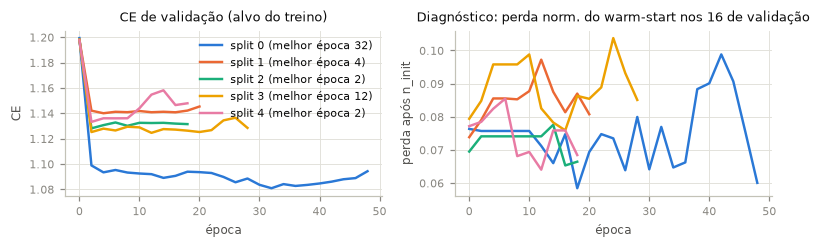

In [3]:
hist = {k: pd.read_csv(cfg.MODELS_DIR / f"our_trained_split{k}_history.csv") for k in range(cfg.N_SPLITS)}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.3))
for k, h in hist.items():
    c = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][k]
    best = tr.loc[tr["split"] == k, "melhor_epoca"].iloc[0]
    axes[0].plot(h["epoch"], h["val_ce"], color=c, lw=1.6, label=f"split {k} (melhor época {best})")
    axes[1].plot(h["epoch"], h["val_regret_warmstart"], color=c, lw=1.6, label=f"split {k}")
axes[0].set(title="CE de validação (alvo do treino)", xlabel="época", ylabel="CE")
axes[1].set(title="Diagnóstico: perda norm. do warm-start nos 16 de validação", xlabel="época", ylabel="perda após n_init")
axes[0].legend(fontsize=7)
fig.tight_layout(); save_fig(fig, "our_trained_treino"); plt.show()

In [4]:
# Referência: a CE de validação de um preditor CONSTANTE — a distribuição média dos alvos dos 80 datasets de treino, igual para
# todo dataset (não olha os dados). Se a Our-Trained fica perto dele, a cabeça aprendeu sobretudo o "prior" da população.
sizes, codes, _ = our_trained.build_group_info(meta.configs)

def soft_ce(target, probs):
    tot, s = 0.0, 0
    for sz in sizes:
        p = np.clip(probs[s:s + sz], 1e-12, None); p = p / p.sum()
        tot -= float((target[s:s + sz] * np.log(p)).sum()); s += sz
    return tot / len(sizes)

rows = []
for k in range(cfg.N_SPLITS):
    idx = meta.split_indices(k)
    tgt = {i: our_trained.soft_targets(meta.Y_valid[i], codes, sizes) for i in idx["train"] + idx["valid"]}
    prior = np.mean([tgt[i] for i in idx["train"]], axis=0)
    rows.append({"split": k, "CE val — inicialização": tr.loc[k, "val_ce_inicial"],
                 "CE val — Our-Trained (melhor época)": tr.loc[k, "val_ce_melhor"],
                 "CE val — prior constante (sem olhar o dataset)": np.mean([soft_ce(tgt[i], prior) for i in idx["valid"]])})
ce_ref = pd.DataFrame(rows).set_index("split")
save_table(ce_ref, "our_trained_ce_vs_prior"); display(ce_ref.round(4))

,CE val — inicialização,CE val — Our-Trained (melhor época),CE val — prior constante (sem olhar o dataset)
split,,,
0,1.1993,1.0808,1.0916
1,1.1977,1.1400,1.1409
2,1.1976,1.1281,1.1309
3,1.1982,1.1245,1.1265
4,1.1976,1.1332,1.1350


A CE de validação cai nas primeiras épocas e depois estaciona; o diagnóstico que interessa à busca (a perda após os 20 pontos
iniciais vindos do vizinho mais próximo, medida nos 16 datasets de validação) não melhora, e em 3 dos 5 splits a época escolhida é
a 2. A tabela acima mostra por quê: a CE alcançada fica no nível do **preditor constante** — o alvo de treino é satisfeito
aprendendo a distribuição média dos hiperparâmetros bons, que não depende do dataset, então nada obriga z a separar datasets
com paisagens diferentes. O efeito disso nas buscas está no `04_Analises.ipynb`.

## Preparação leave-one-dataset-out

Para cada alvo d_t, a preparação das meta-características (descarte de colunas com > 5% de NaN, imputação pela mediana, remoção
de colunas constantes e min-max) é ajustada **só nos outros 119** e aplicada a d_t; a distância é euclidiana. D2V e Our-Trained
usam o extrator do split em que d_t é de teste.

In [5]:
ctx = search.build_context(meta)
raw = search.load_representations(meta.names)
dims = pd.DataFrame({rep: {"tipo": "aprendida" if rep in cfg.REP_LEARNED else "clássica",
                           "colunas brutas": (r[0] if isinstance(r, dict) else r).shape[1],
                           "colunas usadas (LODO, mín–máx)": f"{ctx['dims'][rep].min()}–{ctx['dims'][rep].max()}"}
                     for rep, r in raw.items()}).T
save_table(dims, "representacoes_dimensoes"); display(dims)
nn1 = pd.DataFrame({rep: [meta.names[j] for j in ctx["neighbors"][rep][:, 0]] for rep in cfg.REP_ALL}, index=meta.names)
save_table(nn1, "vizinho_mais_proximo_por_representacao")
print("Vizinho mais próximo (LODO) de alguns alvos:"); display(nn1.head(8))

,tipo,colunas brutas,"colunas usadas (LODO, mín–máx)"
PyMFE,clássica,111,102–102
MF1,clássica,41,28–28
MF2,clássica,22,22–22
D2V,aprendida,32,32–32
Our-Trained,aprendida,1024,1024–1024


Vizinho mais próximo (LODO) de alguns alvos:


,PyMFE,MF1,MF2,D2V,Our-Trained
abalone,waveform,contrac,waveform,seeds,seeds
acute-inflammation,acute-nephritis,monks-3,monks-3,acute-nephritis,acute-nephritis
acute-nephritis,acute-inflammation,acute-inflammation,monks-1,acute-inflammation,acute-inflammation
adult,bank,magic,connect-4,titanic,chess-krvkp
annealing,horse-colic,oocytes_merluccius_states_2f,oocytes_merluccius_states_2f,statlog-shuttle,arrhythmia
arrhythmia,musk-1,semeion,semeion,statlog-shuttle,oocytes_trisopterus_nucleus_2f
audiology-std,soybean,soybean,soybean,thyroid,spambase
balance-scale,hayes-roth,energy-y1,energy-y1,wine,titanic
